# 07d — Semantic Alignment

## Objective

This notebook replaces the purely lexical `SequenceMatcher` alignment used in **07c** with a contextual, embedding-based semantic alignment.

The goal is **not** to compute TPI yet.

We want to answer:

> Can contextual semantic alignment identify the original terms/spans that were genuinely changed by anonymization more robustly than surface lexical alignment?

Pipeline:

```text
Original + Anonymized
        ↓
Contextual token embeddings
        ↓
Term-level embeddings
        ↓
Cosine similarity matrix
        ↓
Maximum-weight matching
        ↓
Similarity threshold
        ↓
Affected original terms
```

The resulting `affected_original_indices` can later be passed to the TPI notebook.


## Why semantic alignment?

`SequenceMatcher` relies on surface form and token order. This can create false positives for:

- paraphrases (`live → reside`)
- reordering (`I live in Geneva → In Geneva I live`)
- lexical reformulations.

Semantic alignment instead compares contextual representations.

For two terms $t_i$ and $u_j$:

$$
S_{ij} = \cos(e_i^{orig}, e_j^{anon})
$$

where $e_i$ and $e_j$ are contextual embeddings of the terms.

A pair is considered semantically aligned when:

$$
S_{ij} \geq \tau
$$

where $\tau$ is a tunable threshold.

**Important:** the threshold is an experimental parameter, not a theoretically fixed value.


In [1]:
# Core imports

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from transformers import AutoTokenizer, AutoModel

from scipy.optimize import linear_sum_assignment

from difflib import SequenceMatcher

print("PyTorch:", torch.__version__)


/opt/anaconda3/envs/interview-anon/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0


In [2]:
# Model configuration

MODEL_NAME = "bert-base-uncased"

# Start with a moderate threshold.
# This must be validated on a manually annotated development set.
SIMILARITY_THRESHOLD = 0.80

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()

print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print("Similarity threshold:", SIMILARITY_THRESHOLD)


Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 5736.58it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: bert-base-uncased
Device: cpu
Similarity threshold: 0.8


## 1. Term extraction

We keep the same term definition as in 07a/07c so that the semantic-alignment experiment remains directly comparable to the existing TPI pipeline.

Punctuation is ignored for alignment.

Each term keeps its character span in the original text.


In [3]:
TERM_PATTERN = r"[A-Za-z0-9]+(?:['-][A-Za-z0-9]+)*"

def extract_terms(text):
    """Return lexical terms and their character spans."""
    return [
        {
            "term": m.group(),
            "start": m.start(),
            "end": m.end(),
        }
        for m in re.finditer(TERM_PATTERN, text)
    ]

def normalize_term(term):
    return term.lower()

def show_terms(text):
    return pd.DataFrame(extract_terms(text))

example = "I live in Geneva since 2022."
show_terms(example)


,term,start,end
0,I,0,1
1,live,2,6
2,in,7,9
3,Geneva,10,16
4,since,17,22
5,2022,23,27


## 2. Contextual embeddings for terms

BERT operates on WordPiece tokens rather than our lexical terms.

For example:

```text
Lausanne → ["Laus", "##anne"]
```

We therefore:

1. tokenize the complete sentence with character offsets;
2. identify which WordPiece tokens overlap each lexical term;
3. extract their contextual hidden states;
4. mean-pool the subtoken representations into one embedding per term.

Thus:

$$
e_t = \frac{1}{K}\sum_{k=1}^{K} h_k
$$

The embedding is contextual because it comes from the full sentence.


In [4]:
def term_embeddings(text):
    """
    Compute one contextual BERT embedding per lexical term.

    Returns
    -------
    terms : list of dict
        Terms with character spans.
    embeddings : np.ndarray, shape (n_terms, hidden_size)
        Mean-pooled contextual embedding for each term.
    """
    terms = extract_terms(text)

    if not terms:
        return terms, np.empty((0, model.config.hidden_size), dtype=np.float32)

    encoded = tokenizer(
        text,
        return_tensors="pt",
        return_offsets_mapping=True,
        truncation=True,
        max_length=tokenizer.model_max_length,
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()
    encoded = {k: v.to(DEVICE) for k, v in encoded.items()}

    with torch.no_grad():
        outputs = model(**encoded)

    hidden = outputs.last_hidden_state[0].detach().cpu()

    term_vectors = []

    for term in terms:
        overlapping_token_ids = []

        for token_id, (tok_start, tok_end) in enumerate(offsets):
            # Special tokens generally have (0, 0).
            if tok_end <= tok_start:
                continue

            # Token overlaps the character span of the term.
            if tok_start < term["end"] and tok_end > term["start"]:
                overlapping_token_ids.append(token_id)

        if not overlapping_token_ids:
            raise ValueError(
                f"No tokenizer token found for term: {term['term']!r}"
            )

        vector = hidden[overlapping_token_ids].mean(dim=0)
        term_vectors.append(vector.numpy())

    return terms, np.vstack(term_vectors).astype(np.float32)


# Quick check
text = "I live in Lausanne since 2022."
terms, embeddings = term_embeddings(text)

print("Terms:", [t["term"] for t in terms])
print("Embedding matrix shape:", embeddings.shape)


Terms: ['I', 'live', 'in', 'Lausanne', 'since', '2022']
Embedding matrix shape: (6, 768)


## 3. Cosine similarity matrix

For every original/anonymized term pair:

$$
S_{ij} =
\frac{e_i \cdot e_j}
{\|e_i\|\|e_j\|}
$$

The matrix allows us to inspect which terms are semantically closest.


In [5]:
def cosine_similarity_matrix(A, B):
    """Pairwise cosine similarity between rows of A and B."""
    A_norm = A / np.clip(np.linalg.norm(A, axis=1, keepdims=True), 1e-12, None)
    B_norm = B / np.clip(np.linalg.norm(B, axis=1, keepdims=True), 1e-12, None)
    return A_norm @ B_norm.T


def build_similarity_matrix(original_text, anonymized_text):
    original_terms, original_embeddings = term_embeddings(original_text)
    anonymized_terms, anonymized_embeddings = term_embeddings(anonymized_text)

    if len(original_terms) == 0 or len(anonymized_terms) == 0:
        similarity = np.empty((len(original_terms), len(anonymized_terms)))
    else:
        similarity = cosine_similarity_matrix(
            original_embeddings,
            anonymized_embeddings
        )

    return original_terms, anonymized_terms, similarity


def display_similarity_matrix(original_terms, anonymized_terms, similarity):
    if similarity.size == 0:
        print("Empty similarity matrix.")
        return

    row_labels = [t["term"] for t in original_terms]
    col_labels = [t["term"] for t in anonymized_terms]

    df = pd.DataFrame(
        similarity,
        index=row_labels,
        columns=col_labels
    )

    display(df.round(3))


## 4. Maximum-weight semantic matching

A simple independent `argmax` is not enough because several original terms could select the same anonymized term.

We therefore solve a one-to-one maximum-weight matching problem:

$$
\max_A \sum_{(i,j)\in A} S_{ij}
$$

using `scipy.optimize.linear_sum_assignment`.

The similarity threshold is applied **after** matching.

Pairs below the threshold are treated as unmatched.


In [6]:
def semantic_align(
    original_text,
    anonymized_text,
    similarity_threshold=SIMILARITY_THRESHOLD
):
    """
    Align original and anonymized terms using contextual embeddings.

    Returns a dictionary containing:
      - original_terms
      - anonymized_terms
      - similarity_matrix
      - alignments
      - affected_original_indices
      - affected_original_terms
    """
    original_terms, anonymized_terms, similarity = build_similarity_matrix(
        original_text,
        anonymized_text
    )

    n = len(original_terms)
    m = len(anonymized_terms)

    alignments = []
    matched_original = set()
    matched_anonymized = set()

    if n > 0 and m > 0:
        # linear_sum_assignment minimizes cost, so negate similarity.
        row_ind, col_ind = linear_sum_assignment(-similarity)

        for i, j in zip(row_ind, col_ind):
            score = float(similarity[i, j])

            if score >= similarity_threshold:
                matched_original.add(i)
                matched_anonymized.add(j)

                same_surface = (
                    normalize_term(original_terms[i]["term"])
                    == normalize_term(anonymized_terms[j]["term"])
                )

                status = "exact_match" if same_surface else "semantic_match"

                alignments.append({
                    "original_idx": i,
                    "original_term": original_terms[i]["term"],
                    "anonymized_idx": j,
                    "anonymized_term": anonymized_terms[j]["term"],
                    "similarity": score,
                    "status": status,
                })

    # Original terms that could not be confidently aligned
    # are considered affected.
    affected_original_indices = [
        i for i in range(n)
        if i not in matched_original
    ]

    # Sort alignments by original position.
    alignments = sorted(
        alignments,
        key=lambda x: x["original_idx"]
    )

    affected_original_terms = [
        original_terms[i]["term"]
        for i in affected_original_indices
    ]

    return {
        "original_terms": original_terms,
        "anonymized_terms": anonymized_terms,
        "similarity_matrix": similarity,
        "alignments": alignments,
        "affected_original_indices": affected_original_indices,
        "affected_original_terms": affected_original_terms,
        "unmatched_anonymized_indices": [
            j for j in range(m)
            if j not in matched_anonymized
        ],
    }


## 5. Human-readable alignment table

The table is the main debugging output of this notebook.

Interpretation:

- `exact_match`: same lexical term;
- `semantic_match`: different surface forms but sufficiently similar contextual embeddings;
- affected original terms: no sufficiently strong semantic correspondence;
- unmatched anonymized terms: insertions or new content on the anonymized side.


In [7]:
def alignment_dataframe(result):
    rows = []

    for item in result["alignments"]:
        rows.append({
            "original_idx": item["original_idx"],
            "original_term": item["original_term"],
            "anonymized_idx": item["anonymized_idx"],
            "anonymized_term": item["anonymized_term"],
            "similarity": round(item["similarity"], 4),
            "status": item["status"],
        })

    for i in result["affected_original_indices"]:
        rows.append({
            "original_idx": i,
            "original_term": result["original_terms"][i]["term"],
            "anonymized_idx": None,
            "anonymized_term": None,
            "similarity": None,
            "status": "affected",
        })

    return pd.DataFrame(
        rows,
        columns=[
            "original_idx",
            "original_term",
            "anonymized_idx",
            "anonymized_term",
            "similarity",
            "status",
        ],
    ).sort_values("original_idx").reset_index(drop=True)


def run_alignment_case(original, anonymized, threshold=SIMILARITY_THRESHOLD):
    result = semantic_align(
        original,
        anonymized,
        similarity_threshold=threshold
    )

    print("ORIGINAL:")
    print(original)
    print("\nANONYMIZED:")
    print(anonymized)
    print("\nALIGNMENT:")
    display(alignment_dataframe(result))
    print("\nAffected original terms:")
    print(result["affected_original_terms"])

    return result


# 6. Controlled experiments

We now test the cases where lexical alignment can be problematic.

The goal is not to prove the semantic aligner is correct yet. These are diagnostic tests.


In [8]:
cases = {
    "unchanged": (
        "I live in Geneva.",
        "I live in Geneva."
    ),
    "synonym_paraphrase": (
        "I live in Geneva.",
        "I reside in Geneva."
    ),
    "replacement": (
        "I live in Lausanne.",
        "I live in Geneva."
    ),
    "deletion": (
        "I live in Geneva since 2022.",
        "I live in Geneva."
    ),
    "insertion": (
        "I live in Geneva.",
        "I currently live in Geneva."
    ),
    "reordering": (
        "I live in Geneva.",
        "In Geneva I live."
    ),
    "generalization": (
        "I have two brothers.",
        "I have siblings."
    ),
    "multiple_changes": (
        "I moved to Geneva in 2022.",
        "I moved to Switzerland."
    ),
}

for name, (original, anonymized) in cases.items():
    print("=" * 80)
    print(name.upper())
    result = semantic_align(
        original,
        anonymized,
        similarity_threshold=SIMILARITY_THRESHOLD
    )
    display(alignment_dataframe(result))
    print("Affected:", result["affected_original_terms"])
    print()


UNCHANGED


,original_idx,original_term,anonymized_idx,anonymized_term,similarity,status
0,0,I,0,I,1.0,exact_match
1,1,live,1,live,1.0,exact_match
2,2,in,2,in,1.0,exact_match
3,3,Geneva,3,Geneva,1.0,exact_match


Affected: []

SYNONYM_PARAPHRASE


,original_idx,original_term,anonymized_idx,anonymized_term,similarity,status
0,0,I,0,I,0.9159,exact_match
1,1,live,1,reside,0.8886,semantic_match
2,2,in,2,in,0.9407,exact_match
3,3,Geneva,3,Geneva,0.9656,exact_match


Affected: []

REPLACEMENT


...

Affected: ['I', 'live', 'in', 'Geneva']

GENERALIZATION


,original_idx,original_term,anonymized_idx,anonymized_term,similarity,status
0,0,I,0.0,I,0.9112,exact_match
1,1,have,1.0,have,0.8841,exact_match
2,2,two,NaN,NaN,NaN,affected
3,3,brothers,NaN,NaN,NaN,affected


Affected: ['two', 'brothers']

MULTIPLE_CHANGES


,original_idx,original_term,anonymized_idx,anonymized_term,similarity,status
0,0,I,0.0,I,0.8431,exact_match
1,1,moved,1.0,moved,0.8272,exact_match
2,2,to,2.0,to,0.8515,exact_match
3,3,Geneva,NaN,NaN,NaN,affected
4,4,in,NaN,NaN,NaN,affected
5,5,2022,NaN,NaN,NaN,affected


Affected: ['Geneva', 'in', '2022']



## 7. Visualize a similarity matrix

This is useful for diagnosing whether the embedding space produces sensible correspondences.

Strong diagonal / semantic correspondences should appear as high-similarity cells.


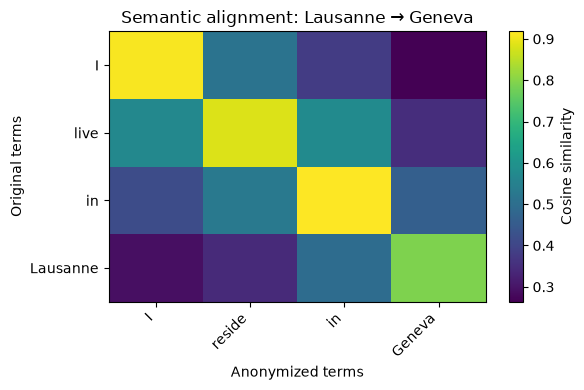

In [9]:
def plot_similarity_matrix(result, title=None):
    S = result["similarity_matrix"]

    if S.size == 0:
        print("Nothing to plot.")
        return

    original_labels = [t["term"] for t in result["original_terms"]]
    anonymized_labels = [t["term"] for t in result["anonymized_terms"]]

    fig, ax = plt.subplots(
        figsize=(
            max(6, 0.9 * len(anonymized_labels)),
            max(4, 0.6 * len(original_labels))
        )
    )

    im = ax.imshow(S, aspect="auto")

    ax.set_xticks(range(len(anonymized_labels)))
    ax.set_xticklabels(anonymized_labels, rotation=45, ha="right")
    ax.set_yticks(range(len(original_labels)))
    ax.set_yticklabels(original_labels)

    ax.set_xlabel("Anonymized terms")
    ax.set_ylabel("Original terms")

    if title:
        ax.set_title(title)

    fig.colorbar(im, ax=ax, label="Cosine similarity")
    plt.tight_layout()
    plt.show()


example_result = semantic_align(
    "I live in Lausanne.",
    "I reside in Geneva.",
    similarity_threshold=SIMILARITY_THRESHOLD
)

plot_similarity_matrix(
    example_result,
    title="Semantic alignment: Lausanne → Geneva"
)


# 8. Compare with SequenceMatcher

This comparison is important because 07c already provides a lexical baseline.

We compare the original terms classified as affected by:

1. `SequenceMatcher`
2. semantic alignment.

This is **not yet a formal benchmark**. A formal benchmark requires manually annotated gold-standard affected spans.


In [10]:
def sequence_matcher_affected_terms(original, anonymized):
    original_terms = extract_terms(original)
    anonymized_terms = extract_terms(anonymized)

    original_norm = [normalize_term(t["term"]) for t in original_terms]
    anonymized_norm = [normalize_term(t["term"]) for t in anonymized_terms]

    matcher = SequenceMatcher(
        None,
        original_norm,
        anonymized_norm,
        autojunk=False
    )

    affected = set()

    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag in {"replace", "delete"}:
            affected.update(range(i1, i2))

    return sorted(affected), [original_terms[i]["term"] for i in sorted(affected)]


comparison_rows = []

for name, (original, anonymized) in cases.items():
    seq_idx, seq_terms = sequence_matcher_affected_terms(
        original,
        anonymized
    )

    sem_result = semantic_align(
        original,
        anonymized,
        similarity_threshold=SIMILARITY_THRESHOLD
    )

    comparison_rows.append({
        "case": name,
        "SequenceMatcher affected": ", ".join(seq_terms),
        "Semantic alignment affected": ", ".join(
            sem_result["affected_original_terms"]
        ),
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)


,case,SequenceMatcher affected,Semantic alignment affected
0,unchanged,,
1,synonym_paraphrase,live,
2,replacement,Lausanne,Lausanne
3,deletion,"since, 2022","since, 2022"
4,insertion,,
5,reordering,"in, Geneva","I, live, in, Geneva"
6,generalization,"two, brothers","two, brothers"
7,multiple_changes,"Geneva, in, 2022","Geneva, in, 2022"


# 9. Threshold sensitivity

The similarity threshold is a critical hyperparameter.

A low threshold tends to accept more semantic matches:

$$
\tau \downarrow
\Rightarrow
\text{fewer terms classified as affected}
$$

A high threshold is stricter:

$$
\tau \uparrow
\Rightarrow
\text{more terms classified as affected}
$$

We therefore inspect the qualitative behavior across thresholds before choosing one.


In [11]:
def threshold_sensitivity(original, anonymized, thresholds=None):
    if thresholds is None:
        thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85]

    rows = []

    # Compute embeddings once for efficiency.
    original_terms, anonymized_terms, similarity = build_similarity_matrix(
        original,
        anonymized
    )

    for threshold in thresholds:
        n = len(original_terms)
        m = len(anonymized_terms)

        matched_original = set()

        if n > 0 and m > 0:
            row_ind, col_ind = linear_sum_assignment(-similarity)

            for i, j in zip(row_ind, col_ind):
                if similarity[i, j] >= threshold:
                    matched_original.add(i)

        affected = [
            original_terms[i]["term"]
            for i in range(n)
            if i not in matched_original
        ]

        rows.append({
            "threshold": threshold,
            "affected_terms": ", ".join(affected),
            "n_affected": len(affected),
        })

    return pd.DataFrame(rows)


threshold_sensitivity(
    "I live in Geneva since 2022.",
    "I reside in Geneva."
)


,threshold,affected_terms,n_affected
0,0.50,"since, 2022",2
1,0.55,"since, 2022",2
2,0.60,"since, 2022",2
3,0.65,"since, 2022",2
4,0.70,"since, 2022",2
5,0.75,"since, 2022",2
6,0.80,"I, since, 2022",3
7,0.85,"I, live, since, 2022",4


# 10. Important limitations

This notebook is an experimental semantic-alignment baseline. It should **not** yet be considered a final alignment method.

### 1. Embedding similarity is not the same as semantic equivalence

Two terms can have similar contextual embeddings while differing in an important factual property.

Example:

```text
Lausanne → Geneva
```

Both are cities and may be semantically close, but the identity of the city is still changed.

### 2. One-to-one matching is restrictive

A transformation can be:

```text
one → many
many → one
```

For example:

```text
two brothers → siblings
```

A future version may need span-level matching rather than strict term-level matching.

### 3. The threshold needs validation

There is no principled reason to assume that 0.70 is optimal.

The threshold should eventually be selected using a manually annotated development set.

### 4. BERT contextual embeddings are not guaranteed to give the best alignment

This notebook establishes a strong baseline. More specialized alignment methods can be evaluated later if necessary.

### 5. No TPI/TPS is computed here

The only output relevant to the next stage is:

```python
result["affected_original_indices"]
```

This separation is intentional.


## Final pipeline under evaluation

Current baseline:

```text
Original
   ↓
SequenceMatcher
   ↓
Affected spans
   ↓
TPI
```

Candidate improved pipeline:

```text
Original + Anonymized
        ↓
Semantic alignment
        ↓
Affected spans
        ↓
TPI
```

Possible future extension:

```text
Semantic alignment
        ↓
Original ↔ Replacement
        ↓
TPS
```

**07d stops before TPI/TPS. Its sole purpose is to evaluate the alignment step.**
